In [1]:
import numpy as np
import scipy.linalg as la
from data import init_geodesic
from solver import GeodesicEstimator
from utils import projection_mse, compute_PSNR, compute_SSIM, compute_RMSE, normalize_np
from data_obs import generate_mc
from altmin import fit_altmin
from functools import partial
from skimage.metrics import peak_signal_noise_ratio as psnr
import matplotlib.pyplot as plt

## Processing Data

In [2]:
# with np.load('img_utils/plane_data_new.npz') as data:
with np.load('img_utils/orig_mouse_data.npz') as data:
    data = data['arr_0']

In [3]:
x, y = data.shape[0], data.shape[1]
frames = data.shape[2]

In [4]:
print(x, y, frames)

70 100 90


In [5]:
vec_data = np.reshape(data, (-1, frames), order='F')
vec_data = vec_data / 255
vec_data_norm = vec_data - np.mean(vec_data, axis=0)

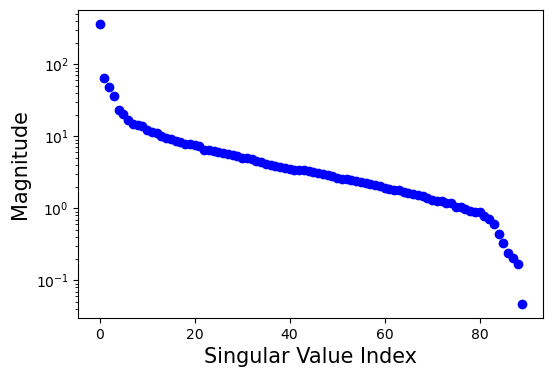

In [6]:
s = np.linalg.svd(vec_data)
fig, ax = plt.subplots(figsize=(6, 4))  # Width = 8, Height = 6 (inches)

# Plot the explained variance
ax.scatter(np.arange(s[1].shape[0]), s[1], marker='o', color='b')

# Add titles and labels
ax.set_xlabel(rf'Singular Value Index', fontsize=15)
ax.set_ylabel('Magnitude', fontsize=15)
ax.set_yscale('log')
# ax.legend(fontsize=12)
fig.savefig('mouse_svals.png', dpi=500, bbox_inches="tight")

In [7]:
data.shape

(70, 100, 90)

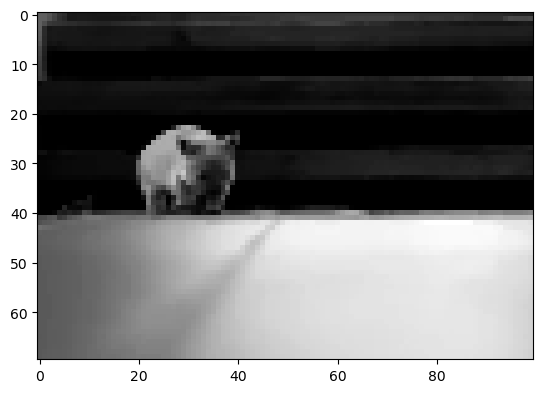

In [8]:
plt.imshow(data[:, :, 10], cmap='gray')

In [9]:
Xs = []

ell = 4 # Number of data samples per time index

st = 0
en = ell

for i in range(frames // ell):
    Xs.append(vec_data_norm[:, st:en])
    
    st += ell
    en += ell
    
T = len(Xs)

## Initialization

In [10]:
def spectral_init(Ys, frac_observed):
    """
    Performing spectral initialization for missing data case.
    """

    T = len(Ys)
    ell = Ys[0].shape[1]
    
    Xs_init = []

    for t in range(T):
        temp = []
        for i in range(ell):
            spect_mat = np.expand_dims( (1 / frac_observed)*Ys[t][:, i], axis=1 )
            temp.append( np.expand_dims(np.linalg.svd(spect_mat)[0][:, 0], axis=1) )

        Xs_init.append(np.concatenate(temp, axis=1))
        
    return Xs_init

In [11]:
def obj_func(Ys, Xs, forward, mask):
    """
    Function for computing objective function value.
    """

    if isinstance(Ys, list):
        Ys = np.concatenate(Ys, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(mask, list):
        mask = np.concatenate(mask, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]


def recovery(Xs, true_Xs):
    """
    Function for computing objective function value.
    """

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    if isinstance(Xs, list):
        Xs = np.concatenate(Xs, axis=1)

    return np.linalg.norm( Ys- forward(Xs, mask) )**2 / Xs.shape[1]

## Driver Code

In [12]:
FRAC_OBSERVED = 0.5
SIGMA = 0.01

NTRIALS = 1
NITERS = 30
RANK = 5



In [13]:
psnr_k_geodesic = np.zeros((NTRIALS, ))
ssim_k_geodesic = np.zeros((NTRIALS, ))
rmse_k_geodesic = np.zeros((NTRIALS, ))

for trial in range( NTRIALS ):
    print('Trial Number: ', trial)

    # Generating data
    forward, transpose, masks = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,frac_observed=FRAC_OBSERVED)

    # Generate masked data
    Ys = []

    for i, Xi in enumerate(Xs):
        Ys.append( forward(Xi, masks[i]) + np.random.randn(*Xi.shape)*SIGMA )

    # Initializing
    Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)
    geo = init_geodesic(d=x*y, k=RANK, Xs=Xs_init, init="pca") # Initialize geodesic
    ts = np.linspace(0.0, 1.0, T+60, endpoint=False)[30:-30]  # Timestamps

    data_init = {
    "Xs":            Xs_init,
    "ts":            ts,
    "measurements":  Ys,
    "forward":       forward,
    "transpose":     transpose,
    "masks":         masks,
    }
        
    # Initial computations
    rmse_k_geodesic[trial, ] = compute_RMSE(data_init["Xs"], Xs)
    psnr_k_geodesic[trial, ] = compute_PSNR(data_init["Xs"], Xs)
    ssim_k_geodesic[trial, ] = compute_SSIM(data_init["Xs"], Xs)
        
    def callback(itr, geo, data):
        cur_rmse = compute_RMSE(data["Xs"], Xs)
        cur_psnr = compute_PSNR(data["Xs"], Xs)
        cur_ssim = compute_SSIM(data["Xs"], Xs)
        
        #if cur_rmse < rmse_k_geodesic[trial, ]:
        #if cur_psnr > psnr_k_geodesic[trial, ]:
        if True:
            rmse_k_geodesic[trial, ] = cur_rmse
            psnr_k_geodesic[trial, ] = cur_psnr
            ssim_k_geodesic[trial, ] = cur_ssim
        else:
            return True
    
        #if itr == NITERS - 1:
        print('(k-Geodesic) Iteration:', itr, 'PSNR:', psnr_k_geodesic[trial,], 'SSIM:', ssim_k_geodesic[trial, ], 'RMSE Error:', rmse_k_geodesic[trial, ])  

        return False

    estimator = GeodesicEstimator(rank=RANK)
    geo_mm_est = estimator.fit(
                    geo=geo,
                    data=data_init,
                    callback=callback,
                    niters=NITERS, 
                    lambda_fn=1.0,           
    )

Trial Number:  0
(k-Geodesic) Iteration: 0 PSNR: 12.22207193710711 SSIM: 0.20288166455449674 RMSE Error: 0.2463412886246524
(k-Geodesic) Iteration: 1 PSNR: 12.226892941510688 SSIM: 0.2039610802035888 RMSE Error: 0.2462071668871582
(k-Geodesic) Iteration: 2 PSNR: 12.261939154726123 SSIM: 0.20490786136556147 RMSE Error: 0.24520220017295125
(k-Geodesic) Iteration: 3 PSNR: 12.297721985123667 SSIM: 0.20592652486226146 RMSE Error: 0.24418394217728043
(k-Geodesic) Iteration: 4 PSNR: 12.333672959596596 SSIM: 0.2069601224603299 RMSE Error: 0.24316508325701378
(k-Geodesic) Iteration: 5 PSNR: 12.369567046577629 SSIM: 0.20800054781823737 RMSE Error: 0.24215220093970888
(k-Geodesic) Iteration: 6 PSNR: 12.405364081507606 SSIM: 0.20903909779524685 RMSE Error: 0.24114635059978193
(k-Geodesic) Iteration: 7 PSNR: 12.441066902107847 SSIM: 0.21007538195523467 RMSE Error: 0.24014738021401977
(k-Geodesic) Iteration: 8 PSNR: 12.476676834808705 SSIM: 0.21110942487370704 RMSE Error: 0.2391551981866106
(k-Geode

In [14]:
X_geo_concat = np.concatenate(geo_mm_est[1]["Xs"], axis=1)
X_concat = np.concatenate(Xs, axis=1)

In [15]:
Ys[0].shape

(7000, 4)

In [16]:
psnr_k_geodesic = np.zeros((NTRIALS, ))
ssim_k_geodesic = np.zeros((NTRIALS, ))
rmse_k_geodesic = np.zeros((NTRIALS, ))

for trial in range( NTRIALS ):
    print('Trial Number: ', trial)

    # Generating data
    forward, transpose, masks = generate_mc(d=Xs[0].shape[0], ell=ell, T=T,frac_observed=FRAC_OBSERVED)

    # Generate masked data
    Ys = []

    for i, Xi in enumerate(Xs):
        Ys.append( forward(Xi, masks[i]) + np.random.randn(*Xi.shape)*SIGMA )

    # Initializing
    Xs_init = spectral_init(Ys=Ys, frac_observed=FRAC_OBSERVED)
    geo = init_geodesic(d=x*y, k=RANK, Xs=Xs_init, init="pca") # Initialize geodesic
    ts = np.linspace(0.0, 1.0, T, endpoint=True)  # Timestamps

    data_init = {
    "Xs":            Xs_init,
    "ts":            ts,
    "measurements":  Ys,
    "forward":       forward,
    "transpose":     transpose,
    "masks":         masks,
    }
        
    # Initial computations
    rmse_k_geodesic[trial, ] = compute_RMSE(data_init["Xs"], Xs)
    psnr_k_geodesic[trial, ] = compute_PSNR(data_init["Xs"], Xs)
    ssim_k_geodesic[trial, ] = compute_SSIM(data_init["Xs"], Xs)
        
    def callback(itr, geo, data):
        cur_rmse = compute_RMSE(data["Xs"], Xs)
        cur_psnr = compute_PSNR(data["Xs"], Xs)
        cur_ssim = compute_SSIM(data["Xs"], Xs)
        
        #if cur_rmse < rmse_k_geodesic[trial, ]:
        #if cur_psnr > psnr_k_geodesic[trial, ]:
        if True:
            rmse_k_geodesic[trial, ] = cur_rmse
            psnr_k_geodesic[trial, ] = cur_psnr
            ssim_k_geodesic[trial, ] = cur_ssim
        else:
            return True
    
        #if itr == NITERS - 1:
        print('(k-Geodesic) Iteration:', itr, 'PSNR:', psnr_k_geodesic[trial,], 'SSIM:', ssim_k_geodesic[trial, ], 'RMSE Error:', rmse_k_geodesic[trial, ])  

        return False

    estimator = GeodesicEstimator(rank=RANK)
    geo_mm_est_orig = estimator.fit(
                    geo=geo,
                    data=data_init,
                    callback=callback,
                    niters=NITERS, 
                    lambda_fn=1.0,           
    )

Trial Number:  0
(k-Geodesic) Iteration: 0 PSNR: 12.218346119713265 SSIM: 0.20202543149997554 RMSE Error: 0.24648564454210597
(k-Geodesic) Iteration: 1 PSNR: 12.352976275560728 SSIM: 0.20656837284853402 RMSE Error: 0.24264468289237492
(k-Geodesic) Iteration: 2 PSNR: 15.591617691264505 SSIM: 0.36591506073692326 RMSE Error: 0.17460105679242435
(k-Geodesic) Iteration: 3 PSNR: 16.404625983938157 SSIM: 0.33108056412866804 RMSE Error: 0.15527189281313547
(k-Geodesic) Iteration: 4 PSNR: 17.225812606589766 SSIM: 0.42680859466009763 RMSE Error: 0.1492163255319033
(k-Geodesic) Iteration: 5 PSNR: 18.783896579231765 SSIM: 0.4355405429108657 RMSE Error: 0.12784566787492674
(k-Geodesic) Iteration: 6 PSNR: 18.26572534535255 SSIM: 0.47680619826716786 RMSE Error: 0.13873044495595188
(k-Geodesic) Iteration: 7 PSNR: 19.933192701412903 SSIM: 0.5110805296516562 RMSE Error: 0.12259414054831187
(k-Geodesic) Iteration: 8 PSNR: 18.89702572932965 SSIM: 0.5153087534080744 RMSE Error: 0.13454815860838176
(k-Geode

In [17]:
X_geo_concat_orig = np.concatenate(geo_mm_est_orig[1]["Xs"], axis=1)


## Post-Processing

In [18]:
psnr_k_mean = np.mean(psnr_k_geodesic)
psnr_k_std = np.std(psnr_k_geodesic)

print('(k) PSNR:', psnr_k_mean, psnr_k_std)

ssim_k_mean = np.mean(ssim_k_geodesic )
ssim_k_std = np.std(ssim_k_geodesic)

print('(k) SSIM:', ssim_k_mean, ssim_k_std)

rmse_k_mean = np.mean(rmse_k_geodesic )
rmse_k_std = np.std(rmse_k_geodesic)

print('(k) RMSE:', rmse_k_mean, rmse_k_std)

(k) PSNR: 20.6071529125159 0.0
(k) SSIM: 0.6414060521389122 0.0
(k) RMSE: 0.12281522612421492 0.0


In [19]:
import matplotlib.pyplot as plt

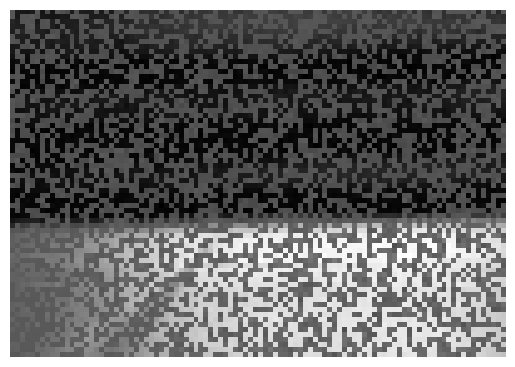

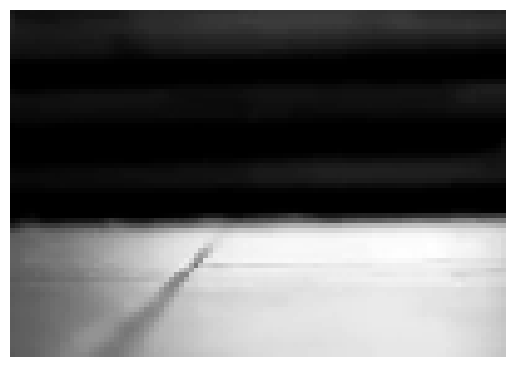

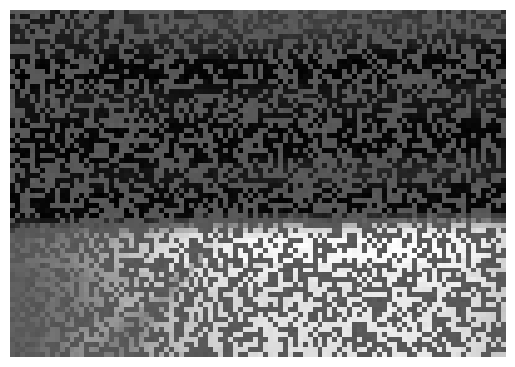

In [20]:
idx = 83
plt.imshow(np.reshape(X_geo_concat[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/geo_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(X_concat[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/true_plane_frame{idx}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(np.concatenate(Ys, axis=1)[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/noisy_plane_frame{idx}.png', bbox_inches='tight', pad_inches=0)
plt.show()

In [21]:
psnr(normalize_np(X_geo_concat[:, idx]), normalize_np(X_concat[:, idx]))


12.541855433445049

In [22]:
psnr(normalize_np(np.concatenate(Ys, axis=1)[:, idx]), normalize_np(X_concat[:, idx]) )


11.722492377095985

In [23]:
noisy_data = np.concatenate(Ys, axis=1)
U, S, V = np.linalg.svd(noisy_data)

k_svd_soln = U[:, :RANK] @ (U[:, :RANK].T @ noisy_data)
twok_svd_soln = U[:, :2*RANK] @ (U[:, :2*RANK].T @ noisy_data)

In [24]:
geo_psnrs = []
geo_psnrs_orig = []

ksvd_psnrs = []
twoksvd_psnrs = []

for idx in range(X_geo_concat.shape[1]):
    geo_psnrs.append(psnr(normalize_np(X_geo_concat[:, idx]), normalize_np(X_concat[:, idx])))
    geo_psnrs_orig.append(psnr(normalize_np(X_geo_concat_orig[:, idx]), normalize_np(X_concat[:, idx])))
    ksvd_psnrs.append( psnr(normalize_np(k_svd_soln[:, idx]), normalize_np(X_concat[:, idx]) ) )
    twoksvd_psnrs.append( psnr(normalize_np(twok_svd_soln[:, idx]), normalize_np(X_concat[:, idx]) ) )
                    
    print(idx, geo_psnrs[-1], ksvd_psnrs[-1], twoksvd_psnrs[-1])

0 12.874266890160557 16.25836015161392 13.667416383834015
1 12.51247288160295 15.769900878195827 13.901864398404054
2 12.460751686540286 15.895110146681857 14.083501520259126
3 12.483178488320895 16.278351598401283 13.913828450377812
4 12.743753069853813 16.184786192974425 12.740150705952862
5 12.693443394372725 16.447239113812852 13.570418840844376
6 12.90458771100461 16.203279271615216 13.529650719511807
7 12.800708678606597 15.771441807321565 14.759279249403471
8 12.98555285863931 15.840798344011514 13.770100696641233
9 12.908101412148463 15.673139781663249 15.778000984233248
10 12.89484474878164 15.735413709216592 14.879548517508178
11 12.700526501925733 15.423837679273387 13.37321412284079
12 12.605572541654142 15.418793601494107 13.441295270587112
13 12.75202633901718 16.034932484290362 14.296353681388354
14 12.72392012782362 15.978911074975727 12.908087558551404
15 12.582070009724413 16.728020834455947 13.499171555649843
16 12.669740228467445 15.513904430226082 13.94834967686914

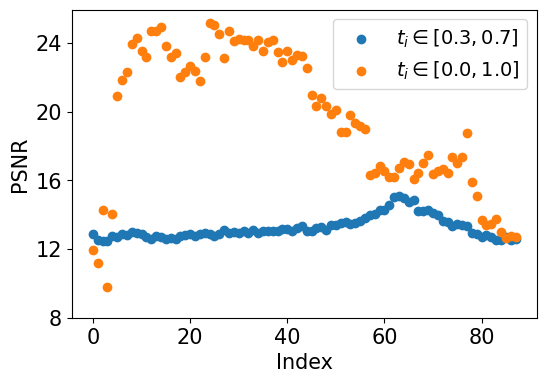

In [25]:
fig, ax = plt.subplots(figsize=(6, 4))  # Set figure size here
ax.scatter(x=np.arange(len(geo_psnrs)), y=geo_psnrs, label=r'$t_i \in [0.3, 0.7]$')
ax.scatter(x=np.arange(len(geo_psnrs)), y=geo_psnrs_orig, label=r'$t_i \in [0.0, 1.0]$')

ticks = plt.yticks()[0]                     # Get current tick positions
int_ticks = [int(tick) for tick in ticks]   # Round to integers
subsampled_ticks = int_ticks[::2]           # Keep every 2nd tick (change to ::3 for every 3rd)

plt.yticks(subsampled_ticks)
# plt.ylim([13.5, 29.75])

# Set labels and title
ax.set_xlabel(r'Index', fontsize=15)
ax.set_ylabel('PSNR', fontsize=15)

# Customize tick parameters
ax.tick_params(axis='both', which='major', labelsize=15)

# Add a legend
ax.legend(fontsize=14)
# plt.savefig('ti_ablation_mouse.pdf', dpi=300, bbox_inches='tight')

In [26]:
print(np.mean(geo_psnrs), np.mean(ksvd_psnrs), np.mean(twoksvd_psnrs))

13.237678795451854 16.192571447355352 14.369569364709356


## SVD Solution

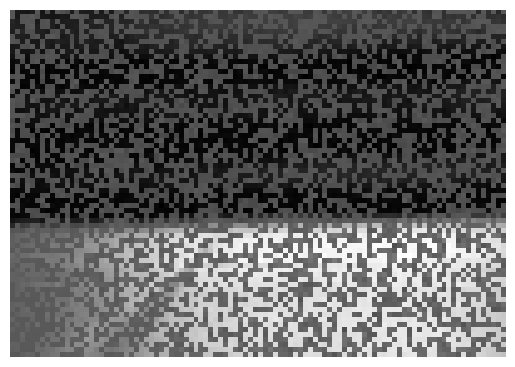

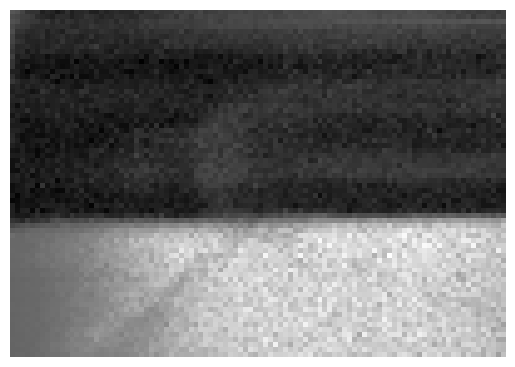

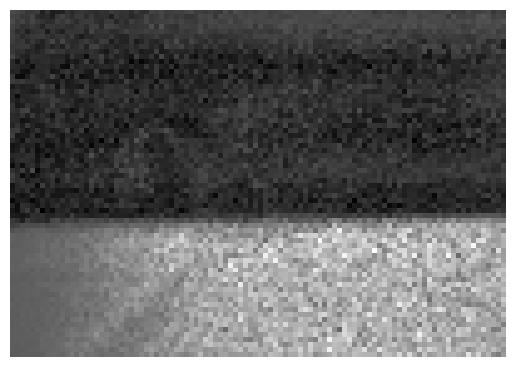

In [27]:
idx = 83

plt.imshow(np.reshape(X_geo_concat[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/geo_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(k_svd_soln[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/svdk_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

plt.imshow(np.reshape(twok_svd_soln[:, idx], (x, y), order='F'), cmap="gray")
plt.axis('off')
plt.savefig(f'curtain_results/svdtwok_plane_frame{idx}_r{RANK}.png', bbox_inches='tight', pad_inches=0)
plt.show()

In [28]:
print(psnr(normalize_np(X_geo_concat[:, idx]), normalize_np(X_concat[:, idx])))
print(psnr(normalize_np(k_svd_soln[:, idx]), normalize_np(X_concat[:, idx])))
print(psnr(normalize_np(twok_svd_soln[:, idx]), normalize_np(X_concat[:, idx])))


12.541855433445049
18.58374544417602
15.603840121905243
